In [1]:
%matplotlib inline
from pathlib import Path
from matplotlib import font_manager
import omicverse as ov
import scanpy as sc
import matplotlib.pyplot as plt

ROOT = Path.cwd()
font_manager.fontManager.addfont(ROOT / 'environment/Arial.ttf')
ov.plot_set(font_path=str(ROOT / 'environment/Arial.ttf'))
sc.settings.set_figure_params(dpi=300, vector_friendly=True)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

/home/hulei/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/hulei/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/hulei/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/hulei/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/hulei/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import anndata.io.read_mtx instead.


/home/hulei/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)


🔬 Starting plot initialization...


Registered as: Arial
🧬 Detecting GPU devices…
✅ NVIDIA CUDA GPUs detected: 8
    • [CUDA 0] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 1] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 2] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 3] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 4] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 5] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 6] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 7] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                           

# T577 六张最终图的复现

从包根目录运行。绘图输入全部位于包内；Arial 使用包内字体文件，无须联网。输出为 figures/ 下六张 PNG 与六张原生 PDF。此 notebook 不运行降采样或 GRN 推断，不读取外部大矩阵。

## 图 1：Relative edge count

同一坐标轴展示两个不同颜色的柱：降采样组总边数与两组共同边数，均除以完整组最终边数。柱高为五次独立 counts50 技术抽样重复的均值，误差线为 ±1 个样本标准差（SD，ddof=1），散点为单次重复。

完整组分母从最终 regulons JSON 计算（68,492 条去重调控边）；五次重复来自已完成的定量结果表。图像保存为 `figures/Relative_edge_count.png`。

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

ROOT = Path.cwd()
network = pd.read_csv(ROOT / 'data/figure_inputs/network_runs.tsv', sep='\t').set_index('run')
full_regulons = json.loads((ROOT / 'data/grn/full/regulons.json').read_text())
full_edge_count = sum(len(set(targets)) for targets in full_regulons.values())
relative_edges = network[['n_edges', 'shared_edges']] / full_edge_count * 100
relative_edges.columns = ['Total inferred edges', 'Retained full-data edges']
summary = pd.DataFrame({'Mean (%)': relative_edges.mean(), 'SD (percentage points)': relative_edges.std(ddof=1)})
summary

                           Mean (%)  SD (percentage points)
Total inferred edges      48.960755                0.527002
Retained full-data edges  30.990189                0.283569

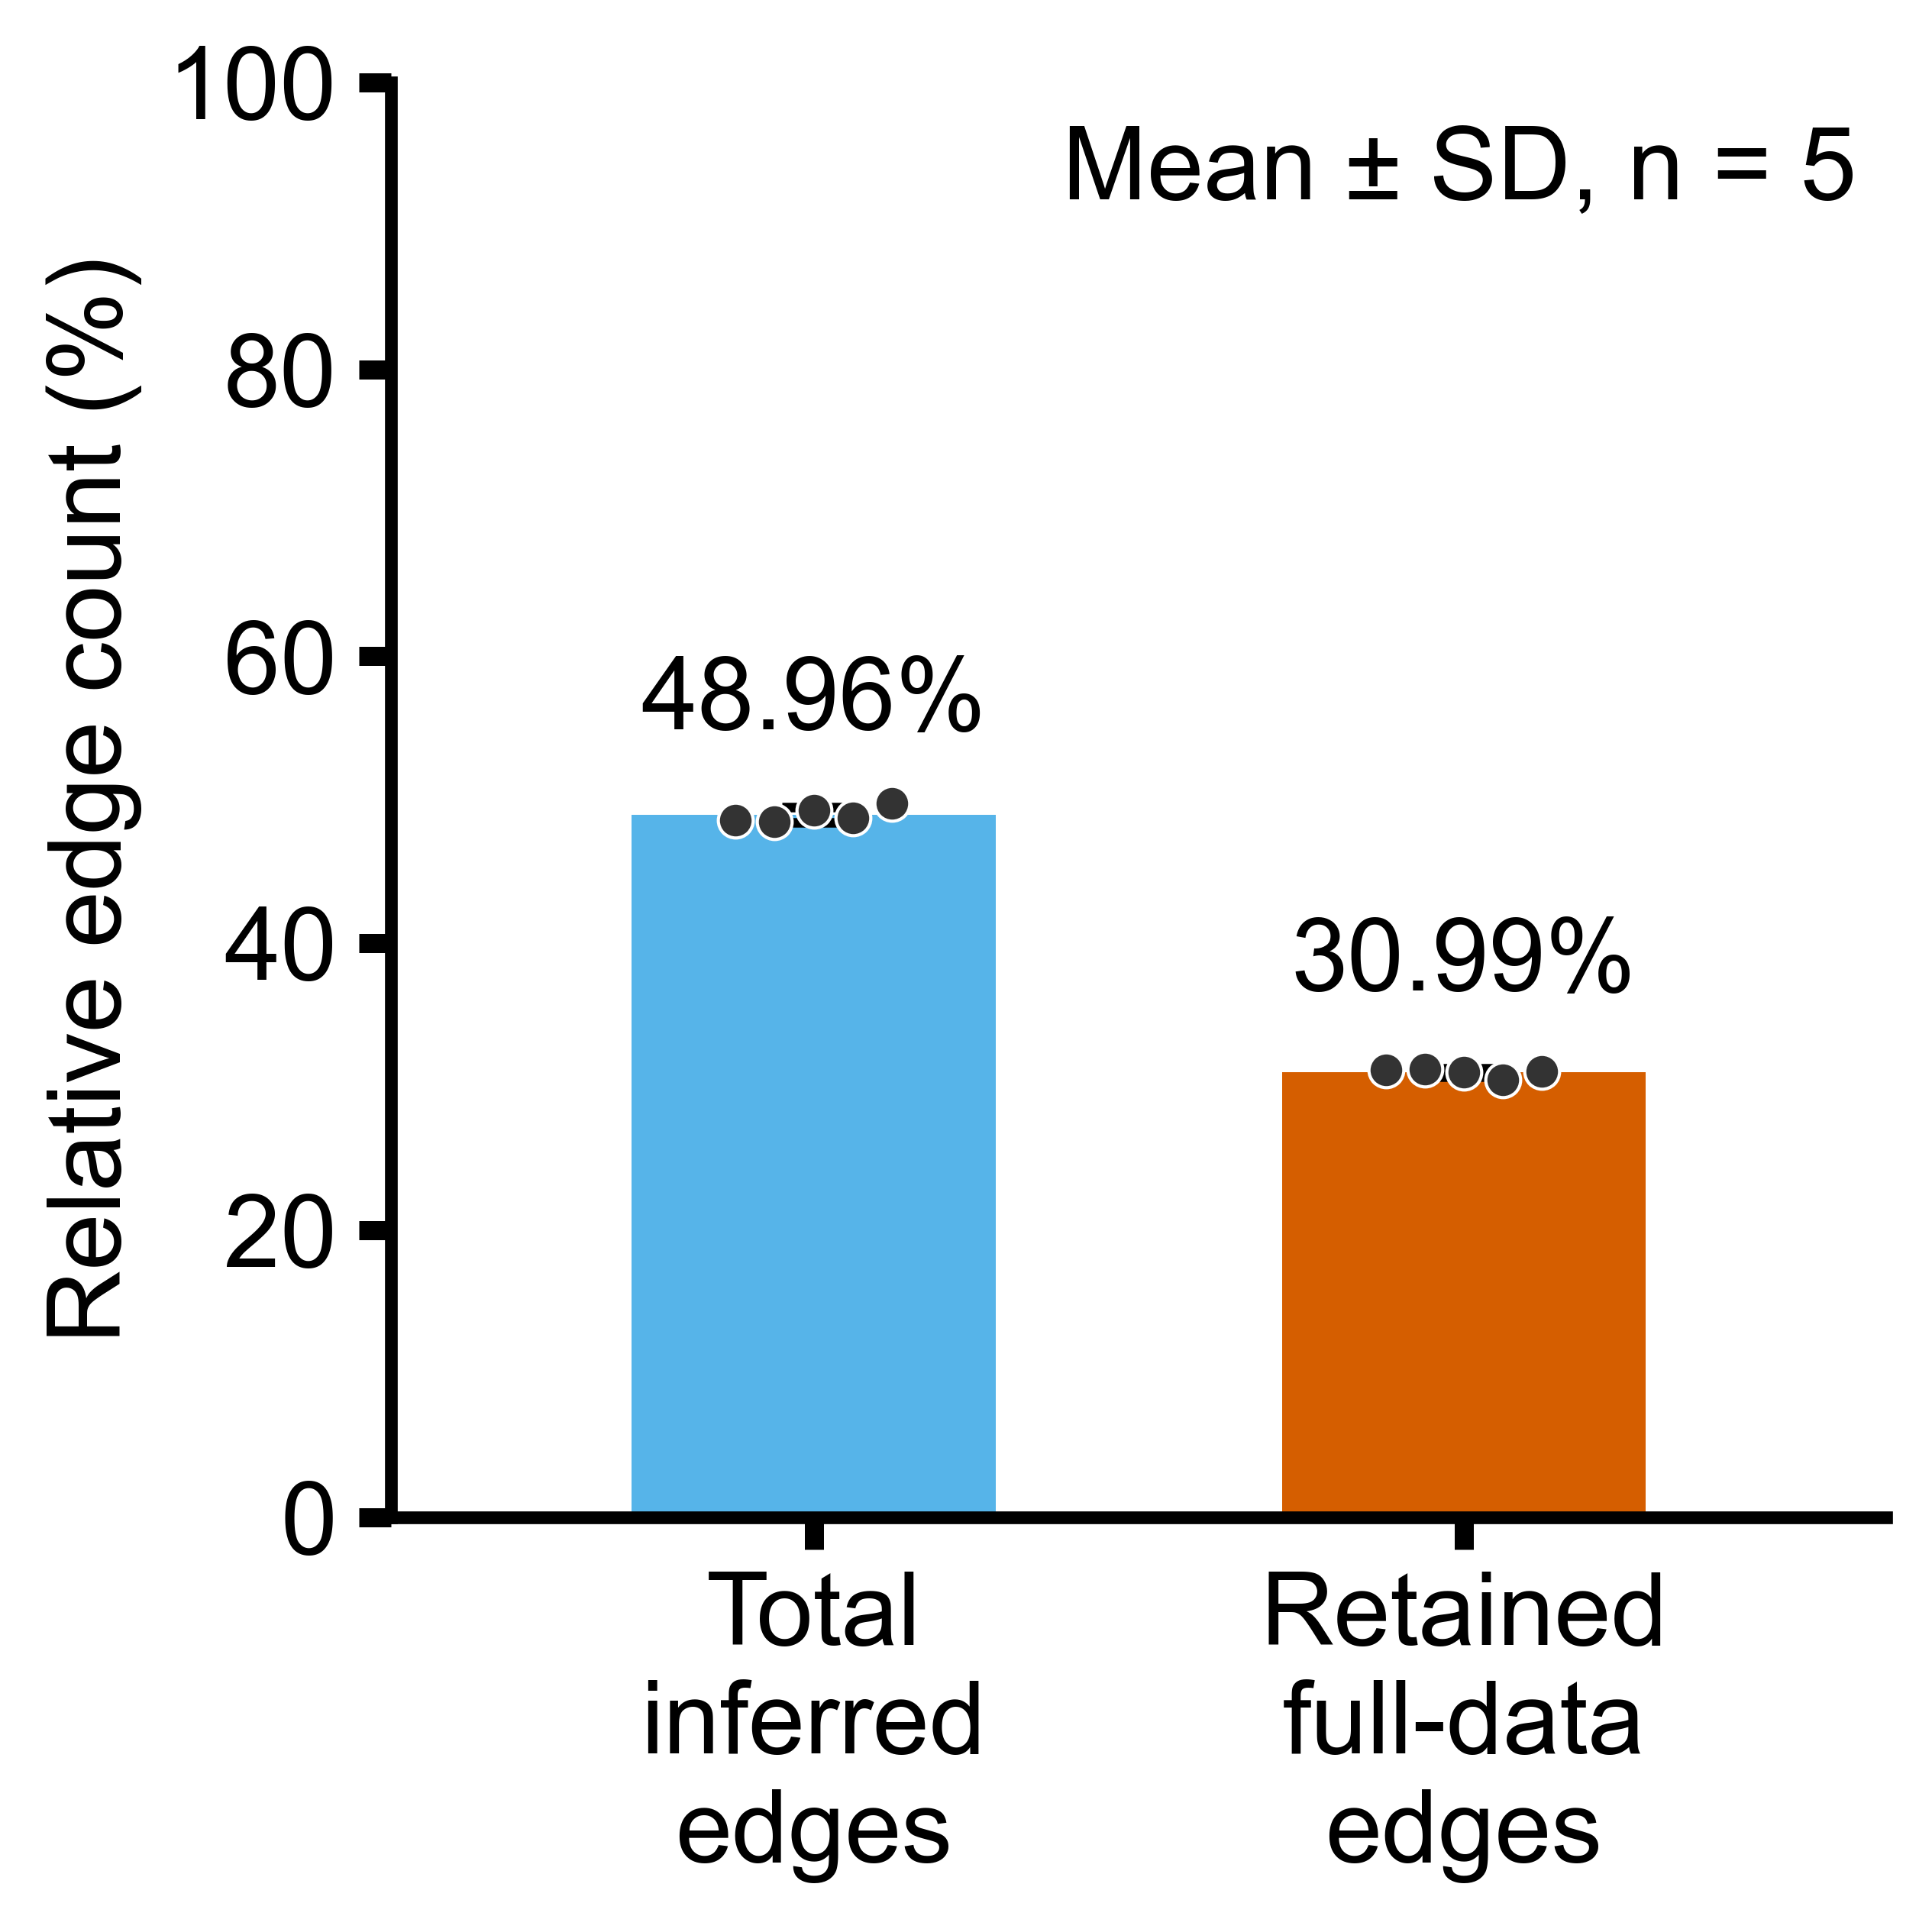

In [3]:
FONT_SIZE = 16
plt.rcParams.update({'font.family': 'Arial', 'axes.grid': False, 'font.size': FONT_SIZE,
                     'axes.labelsize': FONT_SIZE, 'xtick.labelsize': FONT_SIZE, 'ytick.labelsize': FONT_SIZE})
fig, ax = plt.subplots(figsize=(4.5, 4.5))
x = np.arange(2)
means = relative_edges.mean().to_numpy()
sd = relative_edges.std(ddof=1).to_numpy()
ax.bar(x, means, width=0.56, color=['#56B4E9', '#D55E00'], yerr=sd,
       error_kw={'ecolor': 'black', 'elinewidth': 1.5, 'capsize': 5, 'capthick': 1.5}, zorder=2)
for i, values in enumerate(relative_edges.to_numpy().T):
    ax.scatter(i + np.linspace(-0.12, 0.12, len(values)), values, s=30,
               color='#333333', edgecolors='white', linewidths=0.5, zorder=4)
    ax.text(i, means[i] + sd[i] + 4, f'{means[i]:.2f}%', ha='center', va='bottom')
ax.set(xticks=x, xticklabels=['Total\ninferred\nedges', 'Retained\nfull-data\nedges'],
       ylabel='Relative edge count (%)', ylim=(0, 100), yticks=np.arange(0, 101, 20), xlim=(-0.65, 1.65))
ax.tick_params(axis='both', direction='out', length=5, width=3, bottom=True, left=True, top=False, right=False)
for side in ['left', 'bottom']:
    ax.spines[side].set_linewidth(2)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.text(0.98, 0.97, f'Mean ± SD, n = {len(relative_edges)}', transform=ax.transAxes,
        ha='right', va='top', fontsize=FONT_SIZE)
fig.tight_layout()
(ROOT / 'figures').mkdir(exist_ok=True)
fig.savefig(ROOT / 'figures/Relative_edge_count.png', dpi=600, facecolor='white')
fig.savefig(ROOT / 'figures/Relative_edge_count.pdf', dpi=300, facecolor='white')
plt.show()

## 图 2：Relative regulon count

第一根柱为降采样组最终 GRN 的 regulon 总数 / 完整组 regulon 数；第二根柱为两组共同 regulon 数 / 完整组 regulon 数。两根柱的分母均为完整组的 260 个 regulon。

共同 regulon 按名称中的 TF 及调控方向判断，不要求靶基因集合完全一致。当前六组结果中，每个 TF 均对应一个正向 regulon，因此数值与此前的 TF 计数一致。

数据来自 `network_runs.tsv` 的最终 regulon 计数，完整组分母由最终 `regulons.json` 计算。柱高为五次独立 counts50 技术抽样的均值，误差线为 ±1 个样本标准差（SD，ddof=1），散点为单次重复。

沿用图 1 的颜色、16 pt 字体、4.5×4.5 英寸尺寸、2 pt 左下边框与 3 pt 刻度线。图像保存为 `figures/Relative_regulon_count.png`。

In [4]:
relative_regulons = network[['n_regulons', 'shared_regulons']] / len(full_regulons) * 100
relative_regulons.columns = ['Total inferred regulons', 'Retained full-data regulons']
regulon_summary = pd.DataFrame({'Mean (%)': relative_regulons.mean(), 'SD (percentage points)': relative_regulons.std(ddof=1)})
regulon_summary

                              Mean (%)  SD (percentage points)
Total inferred regulons      83.384615                1.571755
Retained full-data regulons  69.076923                1.204037

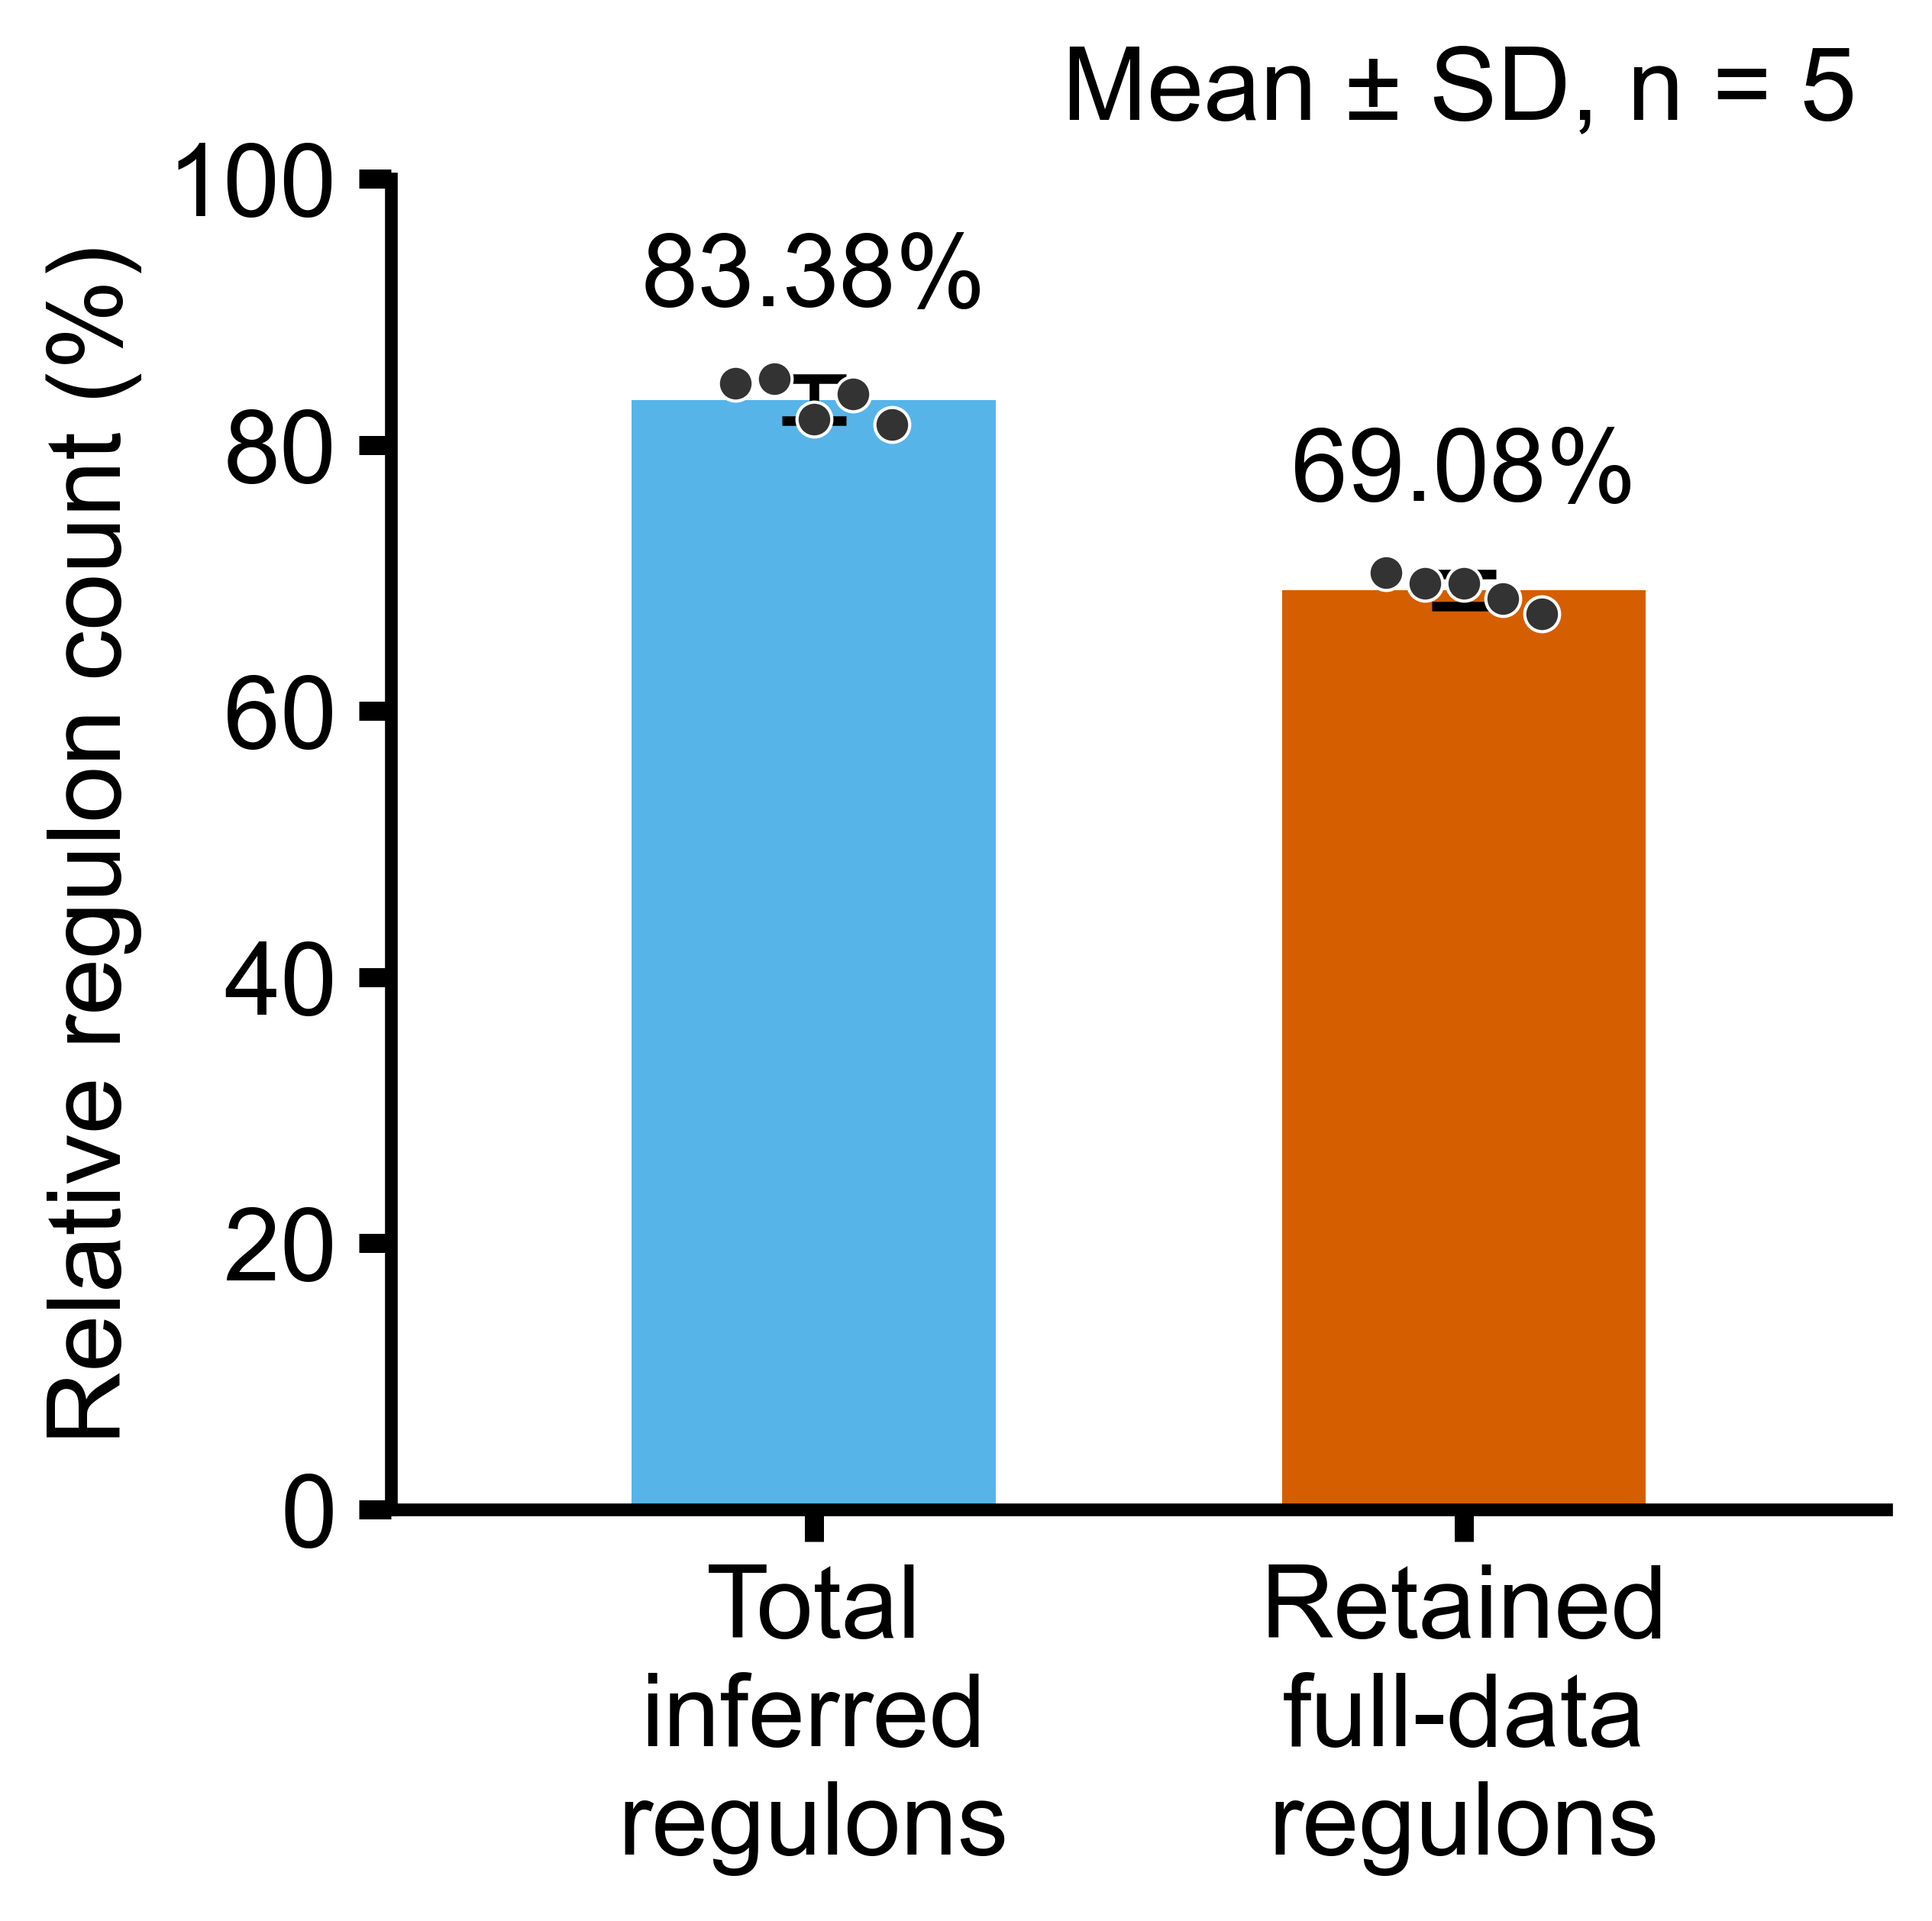

In [5]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
x = np.arange(2)
means = relative_regulons.mean().to_numpy()
sd = relative_regulons.std(ddof=1).to_numpy()
ax.bar(x, means, width=0.56, color=['#56B4E9', '#D55E00'], yerr=sd,
       error_kw={'ecolor': 'black', 'elinewidth': 1.5, 'capsize': 5, 'capthick': 1.5}, zorder=2)
for i, values in enumerate(relative_regulons.to_numpy().T):
    ax.scatter(i + np.linspace(-0.12, 0.12, len(values)), values, s=30,
               color='#333333', edgecolors='white', linewidths=0.5, zorder=4)
    ax.text(i, means[i] + sd[i] + 4, f'{means[i]:.2f}%', ha='center', va='bottom')
ax.set(xticks=x, xticklabels=['Total\ninferred\nregulons', 'Retained\nfull-data\nregulons'],
       ylabel='Relative regulon count (%)', ylim=(0, 100), yticks=np.arange(0, 101, 20), xlim=(-0.65, 1.65))
ax.tick_params(axis='both', direction='out', length=5, width=3, bottom=True, left=True, top=False, right=False)
for side in ['left', 'bottom']:
    ax.spines[side].set_linewidth(2)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.text(0.98, 1.03, f'Mean ± SD, n = {len(relative_regulons)}', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=FONT_SIZE)
fig.tight_layout()
fig.savefig(ROOT / 'figures/Relative_regulon_count.png', dpi=600, facecolor='white')
fig.savefig(ROOT / 'figures/Relative_regulon_count.pdf', dpi=300, facecolor='white')
plt.show()

## 图 3：Shared-regulon AUCell Pearson correlation

每个箱线图对应一次 counts50 重复，仅纳入该次与完整组共有的同名 regulon（TF 和方向一致）。两组各自使用自身推断的靶基因和权重计算原生 AUCell，每个散点为一个共同 regulon 在 117,867 个配对 bin 上的 Pearson 系数。

五组点数依次为 183、181、181、178、175，共 898 个。箱体为第 25–75 百分位，中线为中位数，须为 1.5 IQR 范围内的最远数据点；全部原始点另行叠加，避免重复绘制内置离群点。

Y 轴刻度从 0 开始标注，坐标范围为 −0.35 至 1，以保留全部 8 个负相关值；虚线标记 0。沿用 16 pt 字体、4.5×4.5 英寸尺寸、2 pt 左下边框和 3 pt 刻度线。

图像保存为 `figures/Shared_regulon_Pearson.png`。

In [6]:
shared_pearson = pd.read_csv(ROOT / 'data/figure_inputs/native_shared_regulon_pearson.tsv', sep='\t')
runs = [f'rep{i:02d}' for i in range(1, 6)]
pearson_values = [shared_pearson.loc[shared_pearson['run'] == run, 'pearson'].to_numpy() for run in runs]
shared_pearson.groupby('run')['pearson'].agg(['size', 'median', 'min', 'max'])

       size    median       min       max
run                                      
rep01   183  0.838439 -0.198366  0.957953
rep02   181  0.839613 -0.285936  0.953405
rep03   181  0.839606 -0.104398  0.957422
rep04   178  0.841161 -0.090019  0.958912
rep05   175  0.831836 -0.129458  0.957591

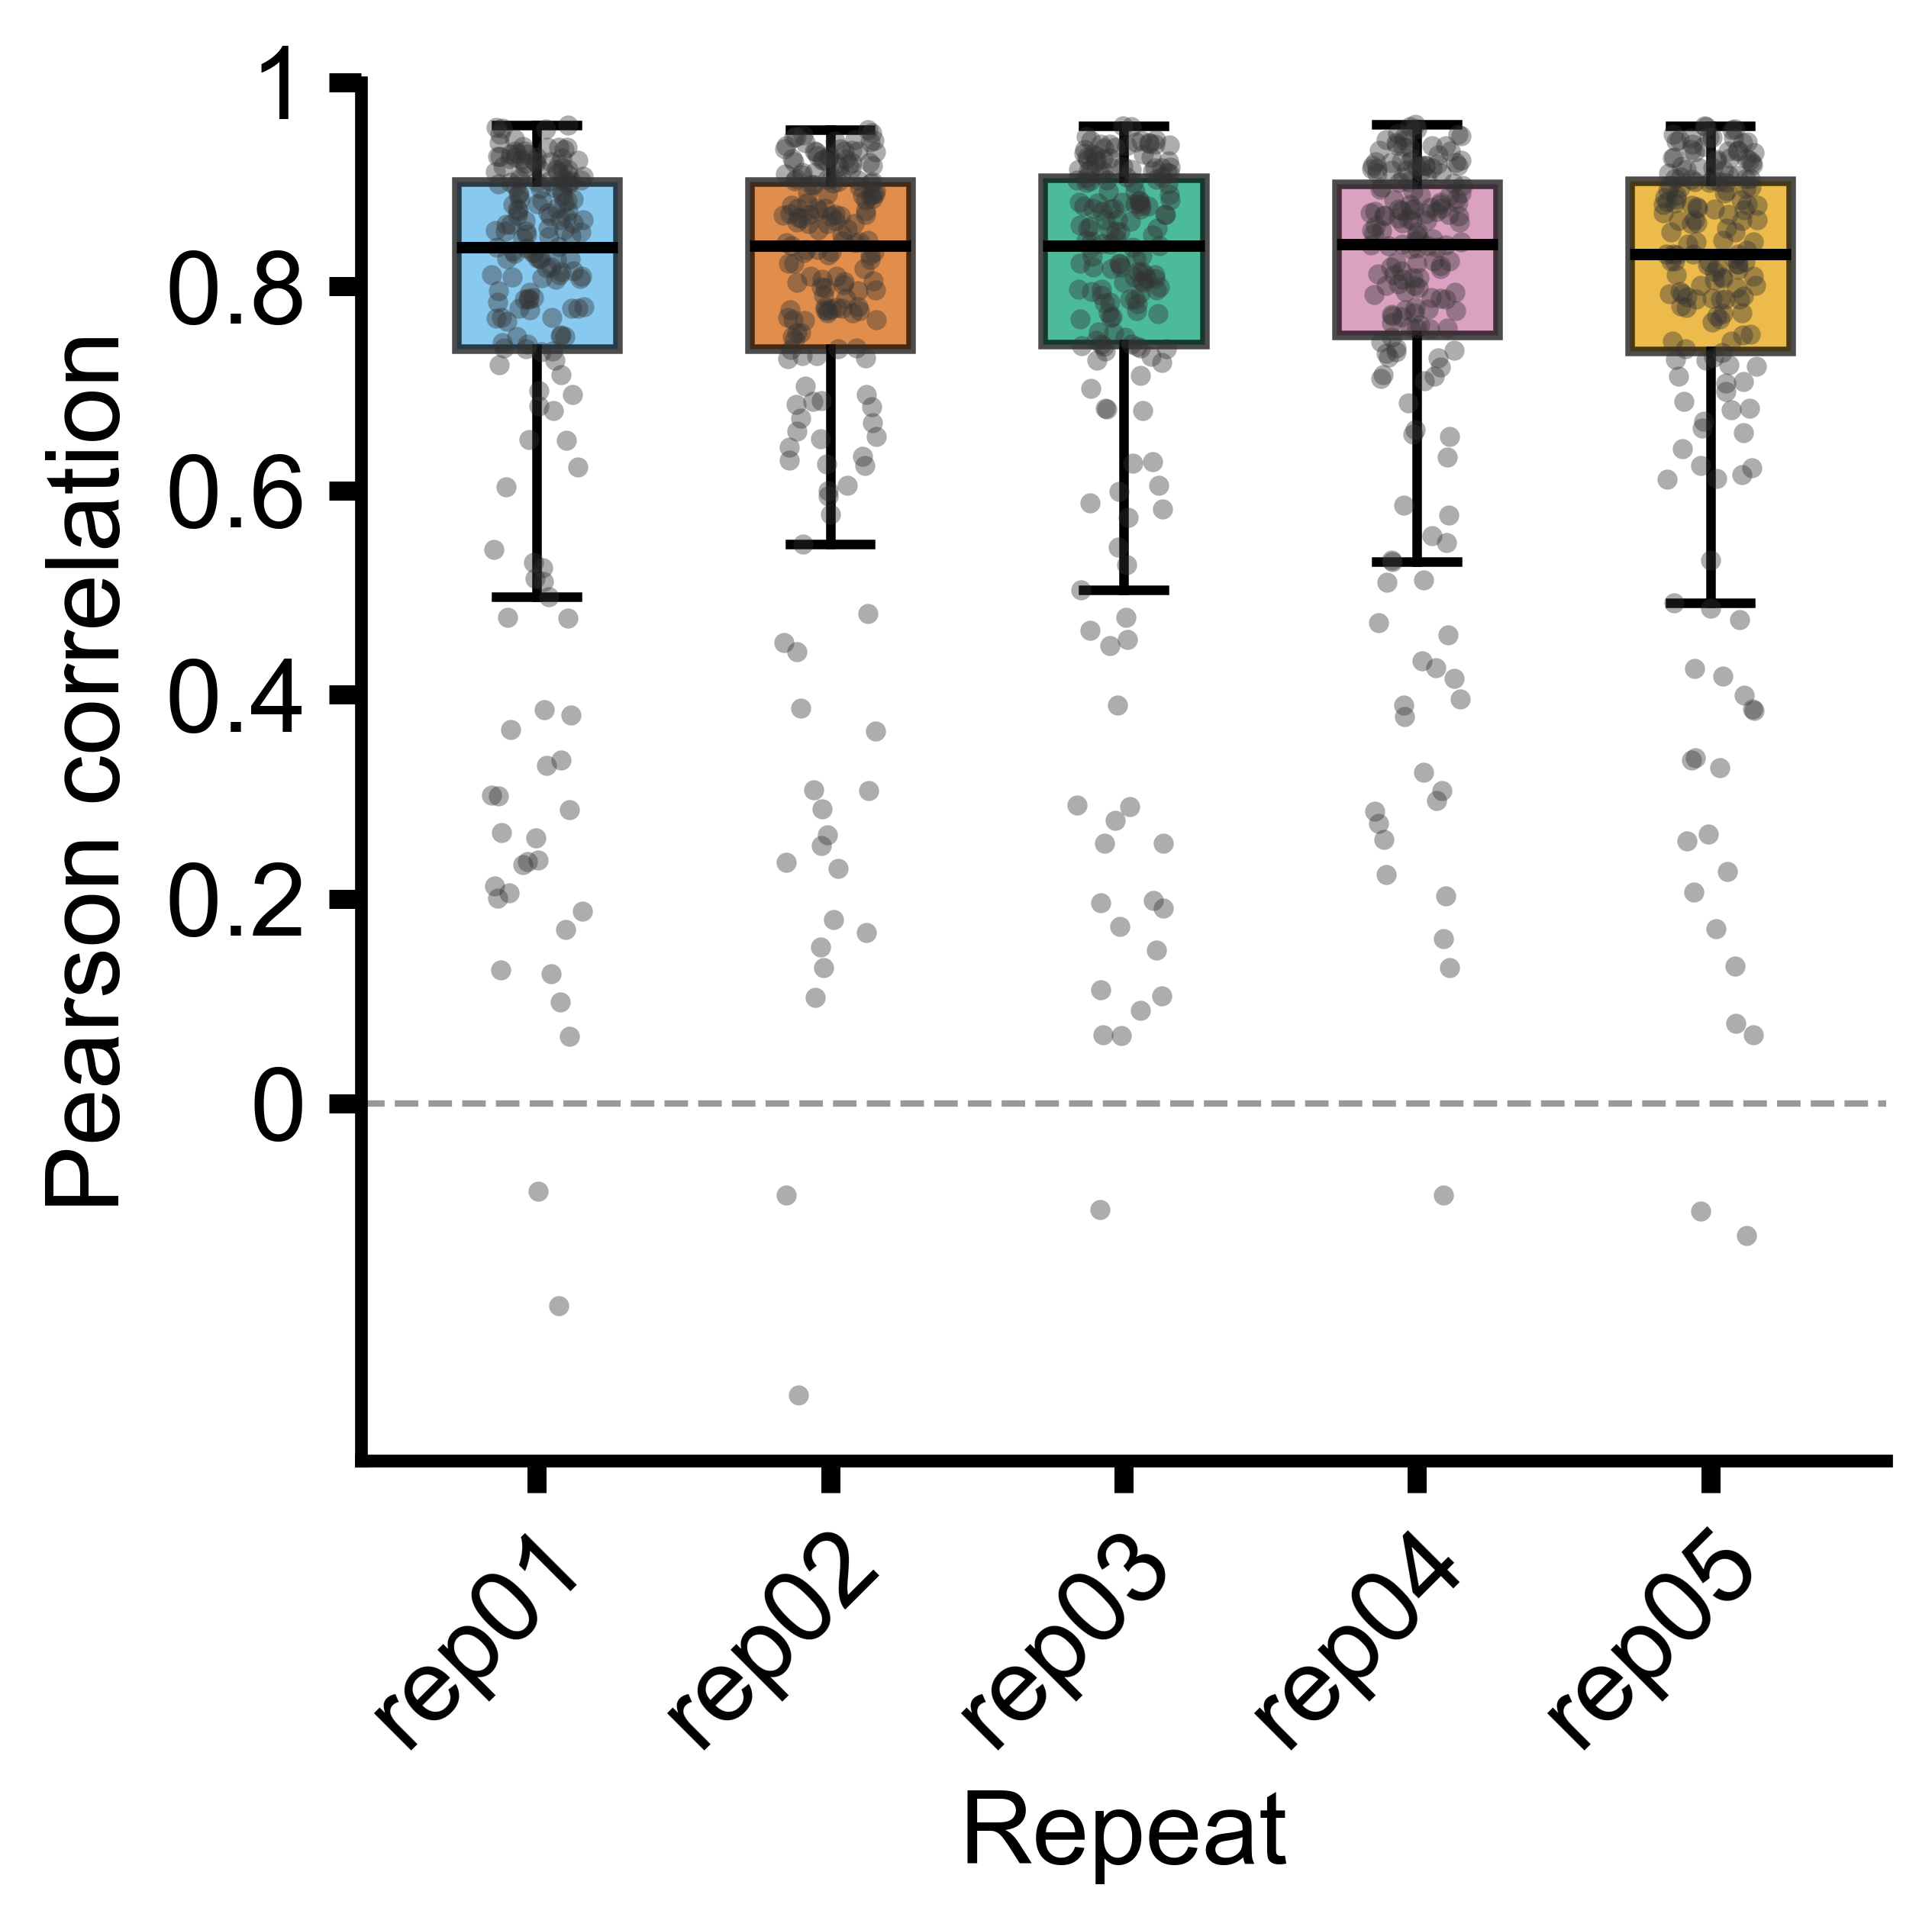

In [7]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
positions = np.arange(1, 6)
colors = ['#56B4E9', '#D55E00', '#009E73', '#CC79A7', '#E69F00']
boxes = ax.boxplot(pearson_values, positions=positions, widths=0.55, patch_artist=True,
                   showfliers=False, whis=1.5,
                   boxprops={'linewidth': 1.5}, whiskerprops={'linewidth': 1.5},
                   capprops={'linewidth': 1.5},
                   medianprops={'color': 'black', 'linewidth': 1.8, 'zorder': 4})
rng = np.random.default_rng(20261106)
for position, values, box, color in zip(positions, pearson_values, boxes['boxes'], colors):
    box.set(facecolor=color, alpha=0.7)
    ax.scatter(position + rng.uniform(-0.16, 0.16, len(values)), values,
               s=10, color='#333333', alpha=0.4, linewidths=0, zorder=3)
ax.axhline(0, color='#999999', linestyle='--', linewidth=1, zorder=0)
ax.set(xticks=positions, xticklabels=runs, xlabel='Repeat', ylabel='Pearson correlation',
       ylim=(-0.35, 1), yticks=np.arange(0, 1.01, 0.2), xlim=(0.4, 5.6))
ax.yaxis.set_major_formatter('{x:g}')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
ax.tick_params(axis='both', direction='out', length=5, width=3, bottom=True, left=True, top=False, right=False)
for side in ['left', 'bottom']:
    ax.spines[side].set_linewidth(2)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(ROOT / 'figures/Shared_regulon_Pearson.png', dpi=600, facecolor='white')
fig.savefig(ROOT / 'figures/Shared_regulon_Pearson.pdf', dpi=300, facecolor='white')
plt.show()

## 图 4：固定 Top100 子集的 Top-k target Jaccard

横轴为 Top20、40、60、80、100。每个箱线图恰好有五个点：各点代表一个 repeat 在其固定 Top100 可比 regulon 子集上的 Jaccard 中位数。箱体及须描述这五个 repeat 中位数的分布，所有点均叠加显示。

各 repeat 的固定模块数分别为 67、60、61、64、62；同一 repeat 内五个 k 使用相同模块名单。这里的点属于技术重复层面，不是逐 regulon 原始 Jaccard。

沿用 16 pt 字体、4.5×4.5 英寸尺寸、2 pt 左下边框和 3 pt 刻度线，Y 轴为 0–1。图像保存为 `figures/Topk_Jaccard_top100_subset.png`。

箱体使用紫色渐变，由浅到深表示 k 从 20 增至 100；颜色表示 Top-k 阈值，灰色点表示五个 repeat 的中位数。

In [8]:
top100_summary = pd.read_csv(ROOT / 'data/figure_inputs/network_topk_top100_subset.tsv', sep='\t')
k_values = [20, 40, 60, 80, 100]
topk_medians = top100_summary.pivot(index='run', columns='k', values='median_jaccard')[k_values]
topk_values = [topk_medians[k].to_numpy() for k in k_values]
topk_medians

k           20        40        60        80        100
run                                                    
rep01  0.538462  0.538462  0.518987  0.495327  0.459854
rep02  0.600000  0.553544  0.558442  0.545930  0.520935
rep03  0.600000  0.568627  0.558442  0.553398  0.538462
rep04  0.509972  0.538462  0.518987  0.488404  0.476035
rep05  0.538462  0.538462  0.538462  0.516622  0.515152

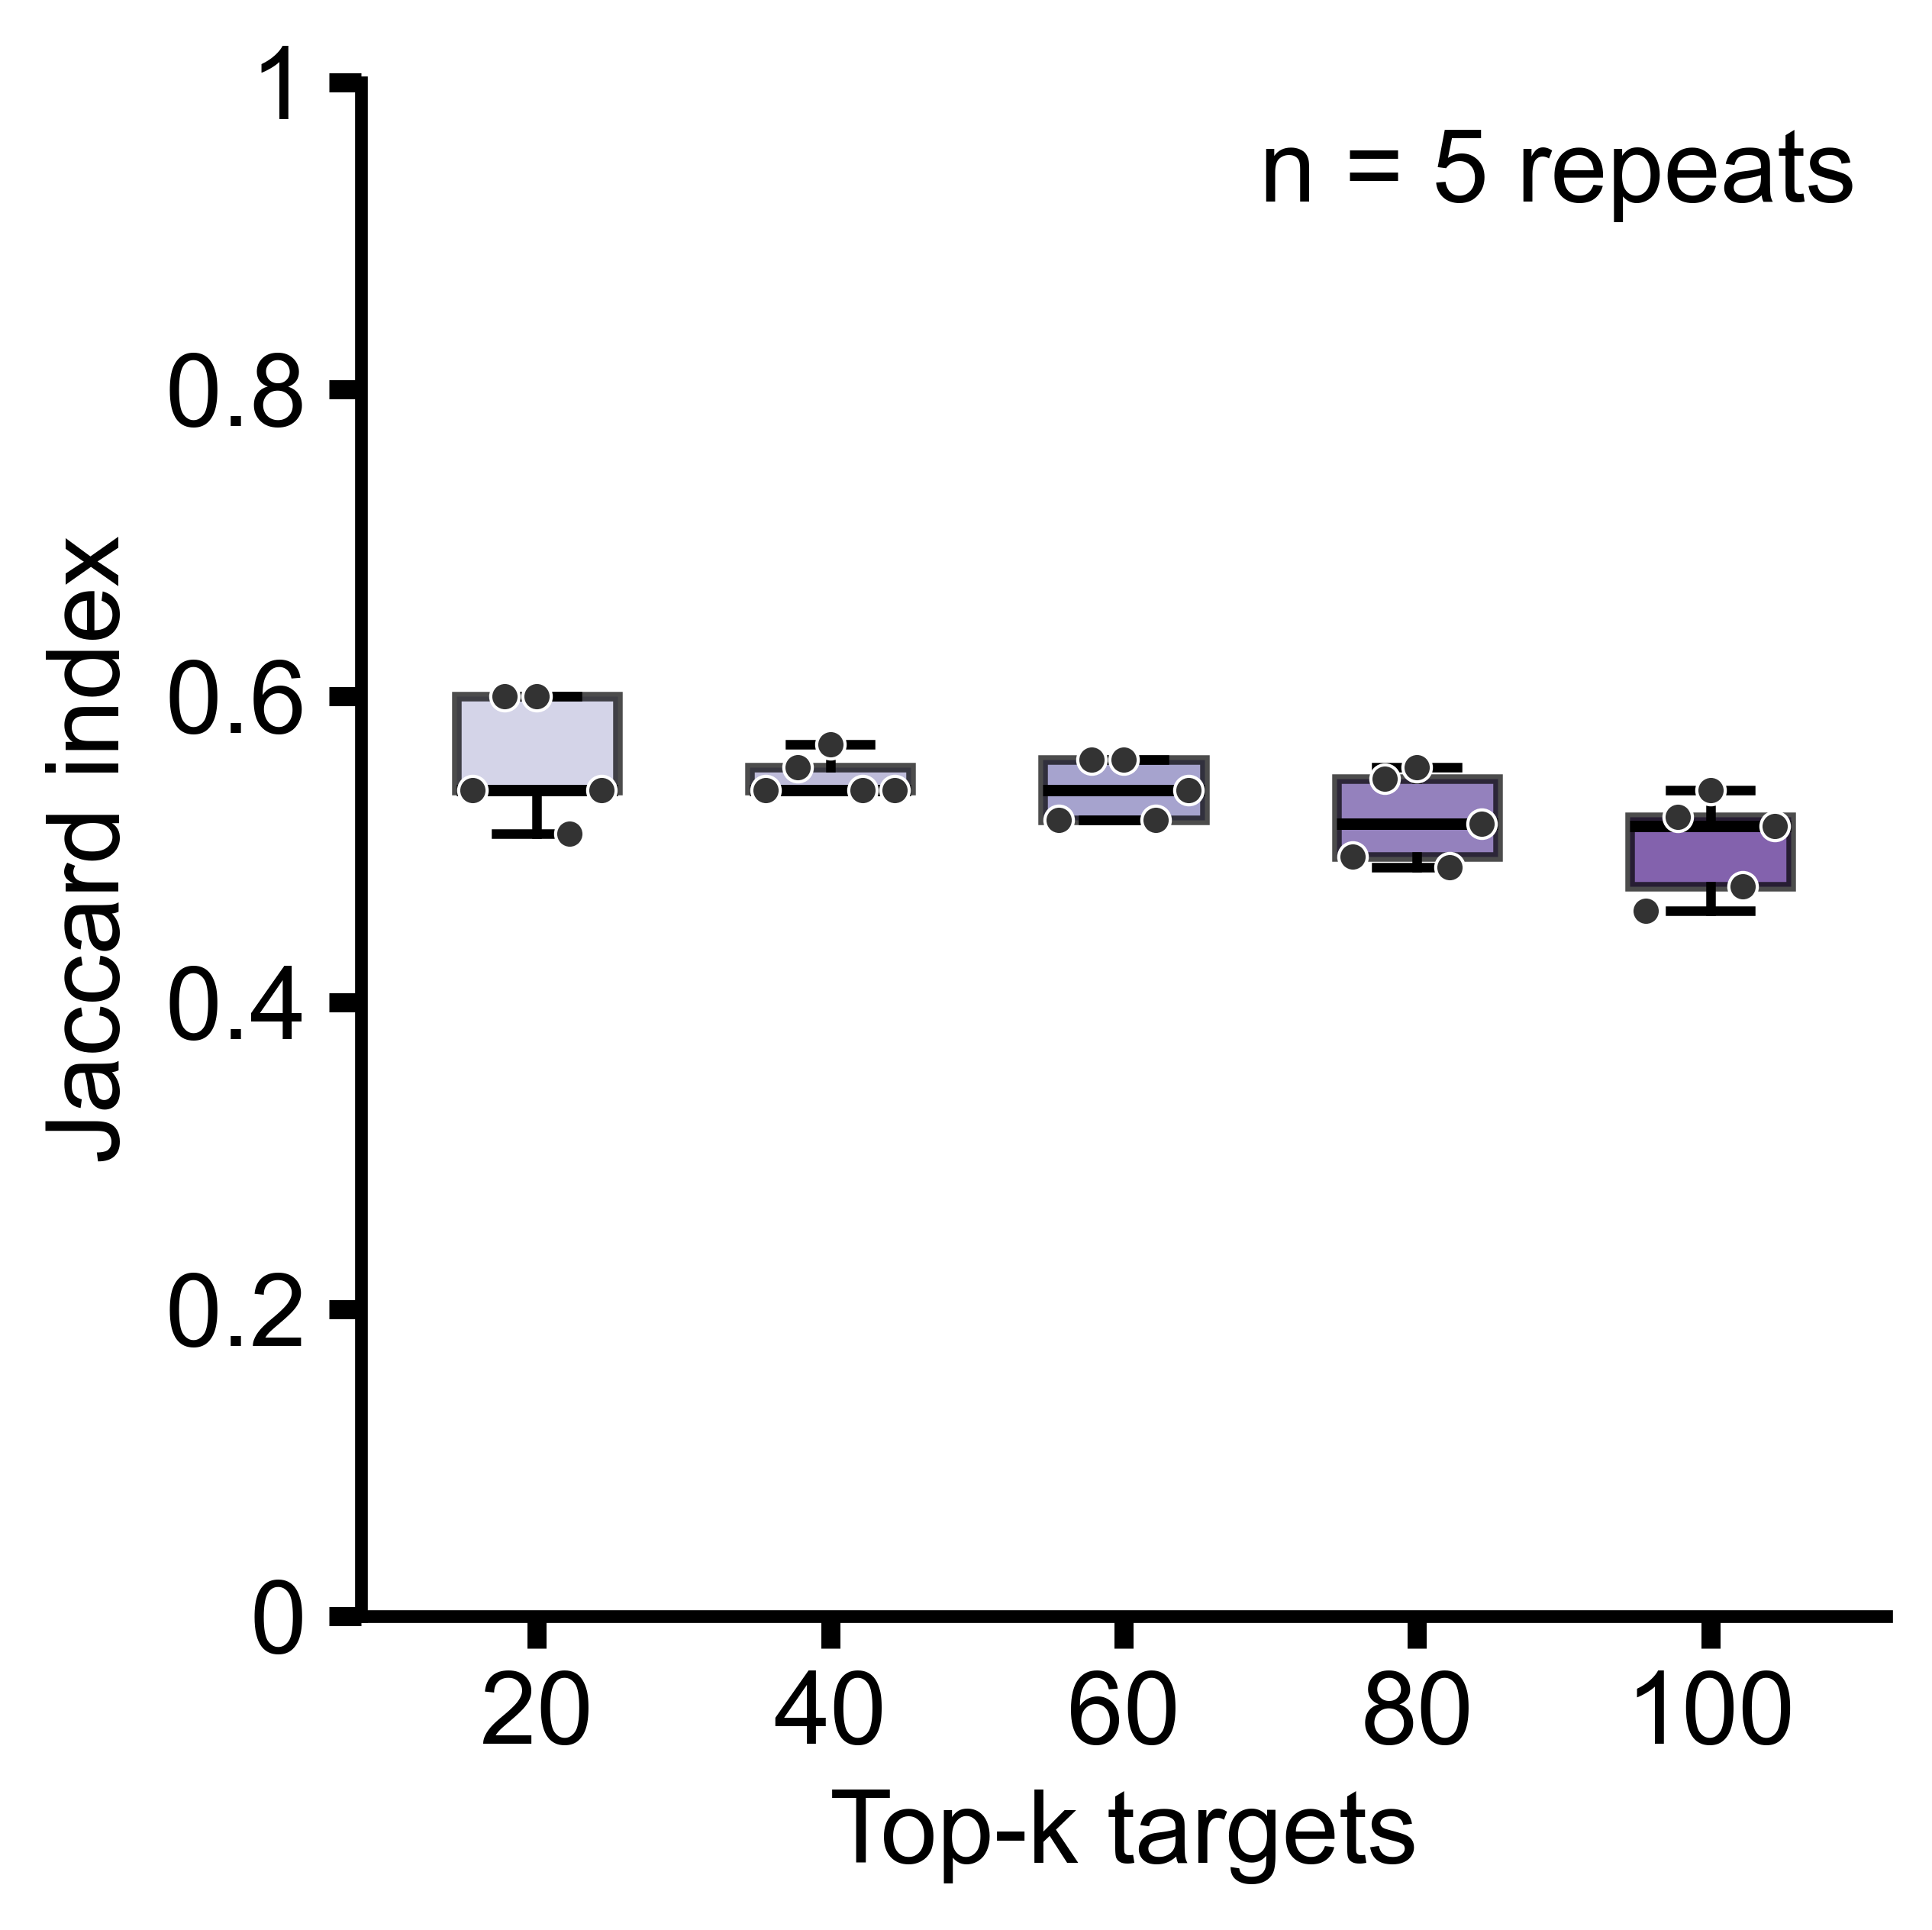

In [9]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
positions = np.arange(1, 6)
colors = plt.cm.Purples(np.linspace(0.35, 0.9, len(k_values)))
boxes = ax.boxplot(topk_values, positions=positions, widths=0.55, patch_artist=True,
                   showfliers=False, whis=1.5,
                   boxprops={'linewidth': 1.5}, whiskerprops={'linewidth': 1.5},
                   capprops={'linewidth': 1.5},
                   medianprops={'color': 'black', 'linewidth': 1.8, 'zorder': 4})
for position, values, box, color in zip(positions, topk_values, boxes['boxes'], colors):
    box.set(facecolor=color, alpha=0.7)
    ax.scatter(position + np.linspace(-0.22, 0.22, len(values)), values,
               s=20, color='#333333', edgecolors='white', linewidths=0.5, zorder=5)
ax.set(xticks=positions, xticklabels=k_values, xlabel='Top-k targets', ylabel='Jaccard index',
       ylim=(0, 1), yticks=np.arange(0, 1.01, 0.2), xlim=(0.4, 5.6))
ax.yaxis.set_major_formatter('{x:g}')
ax.tick_params(axis='both', direction='out', length=5, width=3, bottom=True, left=True, top=False, right=False)
for side in ['left', 'bottom']:
    ax.spines[side].set_linewidth(2)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
ax.text(0.98, 0.97, 'n = 5 repeats', transform=ax.transAxes,
        ha='right', va='top', fontsize=FONT_SIZE)
fig.tight_layout()
fig.savefig(ROOT / 'figures/Topk_Jaccard_top100_subset.png', dpi=600, facecolor='white')
fig.savefig(ROOT / 'figures/Topk_Jaccard_top100_subset.pdf', dpi=300, facecolor='white')
plt.show()

## 图 5–6：TF 表达五分组的模块与靶基因恢复率

仅使用完整组平均 CP10K 固定的五组，每组 52 个 TF；横轴从高到低排列为 **Q5、Q4、Q3、Q2、Q1**。每个箱线图恰有五个点，分别代表一次 counts50 技术重复的组级恢复率，不是 52 个 TF 的逐个结果。箱体为第 25–75 百分位，中线为中位数，须为 1.5 IQR 范围内的最远数据点；叠加全部五个点，隐藏重复的内置离群点。

模块恢复率为该组在降采样中仍有同名、同方向最终 regulon 的 TF 数 / 52。靶基因恢复率沿用前表的边加权口径：该组恢复的原始 TF–target 关系数 / 该组完整组全部 TF–target 关系数；同一个靶基因在不同 TF 下分别计数，不是全网络去重基因比例。Q5→Q1 的固定靶边分母依次为 32,722、17,972、12,803、3,263、1,732。模块缺失时恢复数为 0，仍计入分母。

两图使用相同的 cividis 连续色阶表示 TF 表达组（高表达偏黄、低表达偏蓝），灰色点表示技术重复；色阶与前图的 repeat 分类色及 Top-k 紫色阶分别定义。沿用 16 pt 统一字体、4.5×4.5 英寸尺寸、2 pt 左下边框、3 pt 刻度线，移除右上边框，Y 轴为 0–100%。箱线图使用中位数/IQR/须，不额外叠加 SD 线。

输入为 `tf_expression_quintile_group_runs.tsv`；输出为 `figures/TF_expression_module_recovery.png` 和 `figures/TF_expression_target_recovery.png`。

In [10]:
from IPython.display import display

expression_recovery = pd.read_csv(ROOT / 'data/figure_inputs/tf_expression_quintile_group_runs.tsv', sep='\t')
expression_recovery = expression_recovery.loc[expression_recovery['grouping'] == 'expression_quintile']
expression_order = ['Q5', 'Q4', 'Q3', 'Q2', 'Q1']
expression_modules = expression_recovery.pivot(index='run', columns='quintile', values='module_recovery').loc[runs, expression_order] * 100
expression_targets = expression_recovery.pivot(index='run', columns='quintile', values='edge_weighted_recovery').loc[runs, expression_order] * 100
expression_colors = plt.cm.cividis(np.linspace(0.9, 0.2, len(expression_order)))
display(expression_modules, expression_targets)

quintile         Q5         Q4         Q3         Q2         Q1
run                                                            
rep01     88.461538  94.230769  86.538462  55.769231  26.923077
rep02     90.384615  90.384615  82.692308  53.846154  30.769231
rep03     86.538462  90.384615  90.384615  51.923077  28.846154
rep04     90.384615  92.307692  82.692308  55.769231  21.153846
rep05     90.384615  92.307692  80.769231  48.076923  25.000000

quintile         Q5         Q4         Q3         Q2         Q1
run                                                            
rep01     39.499419  26.162920  23.174256  18.326693   8.314088
rep02     40.220647  25.528600  22.463485  17.223414  11.893764
rep03     39.181590  26.953038  22.104194  17.100827  10.450346
rep04     38.940163  25.144669  22.354136  19.154153   8.545035
rep05     39.560540  25.545293  23.400765  17.989580   8.718245

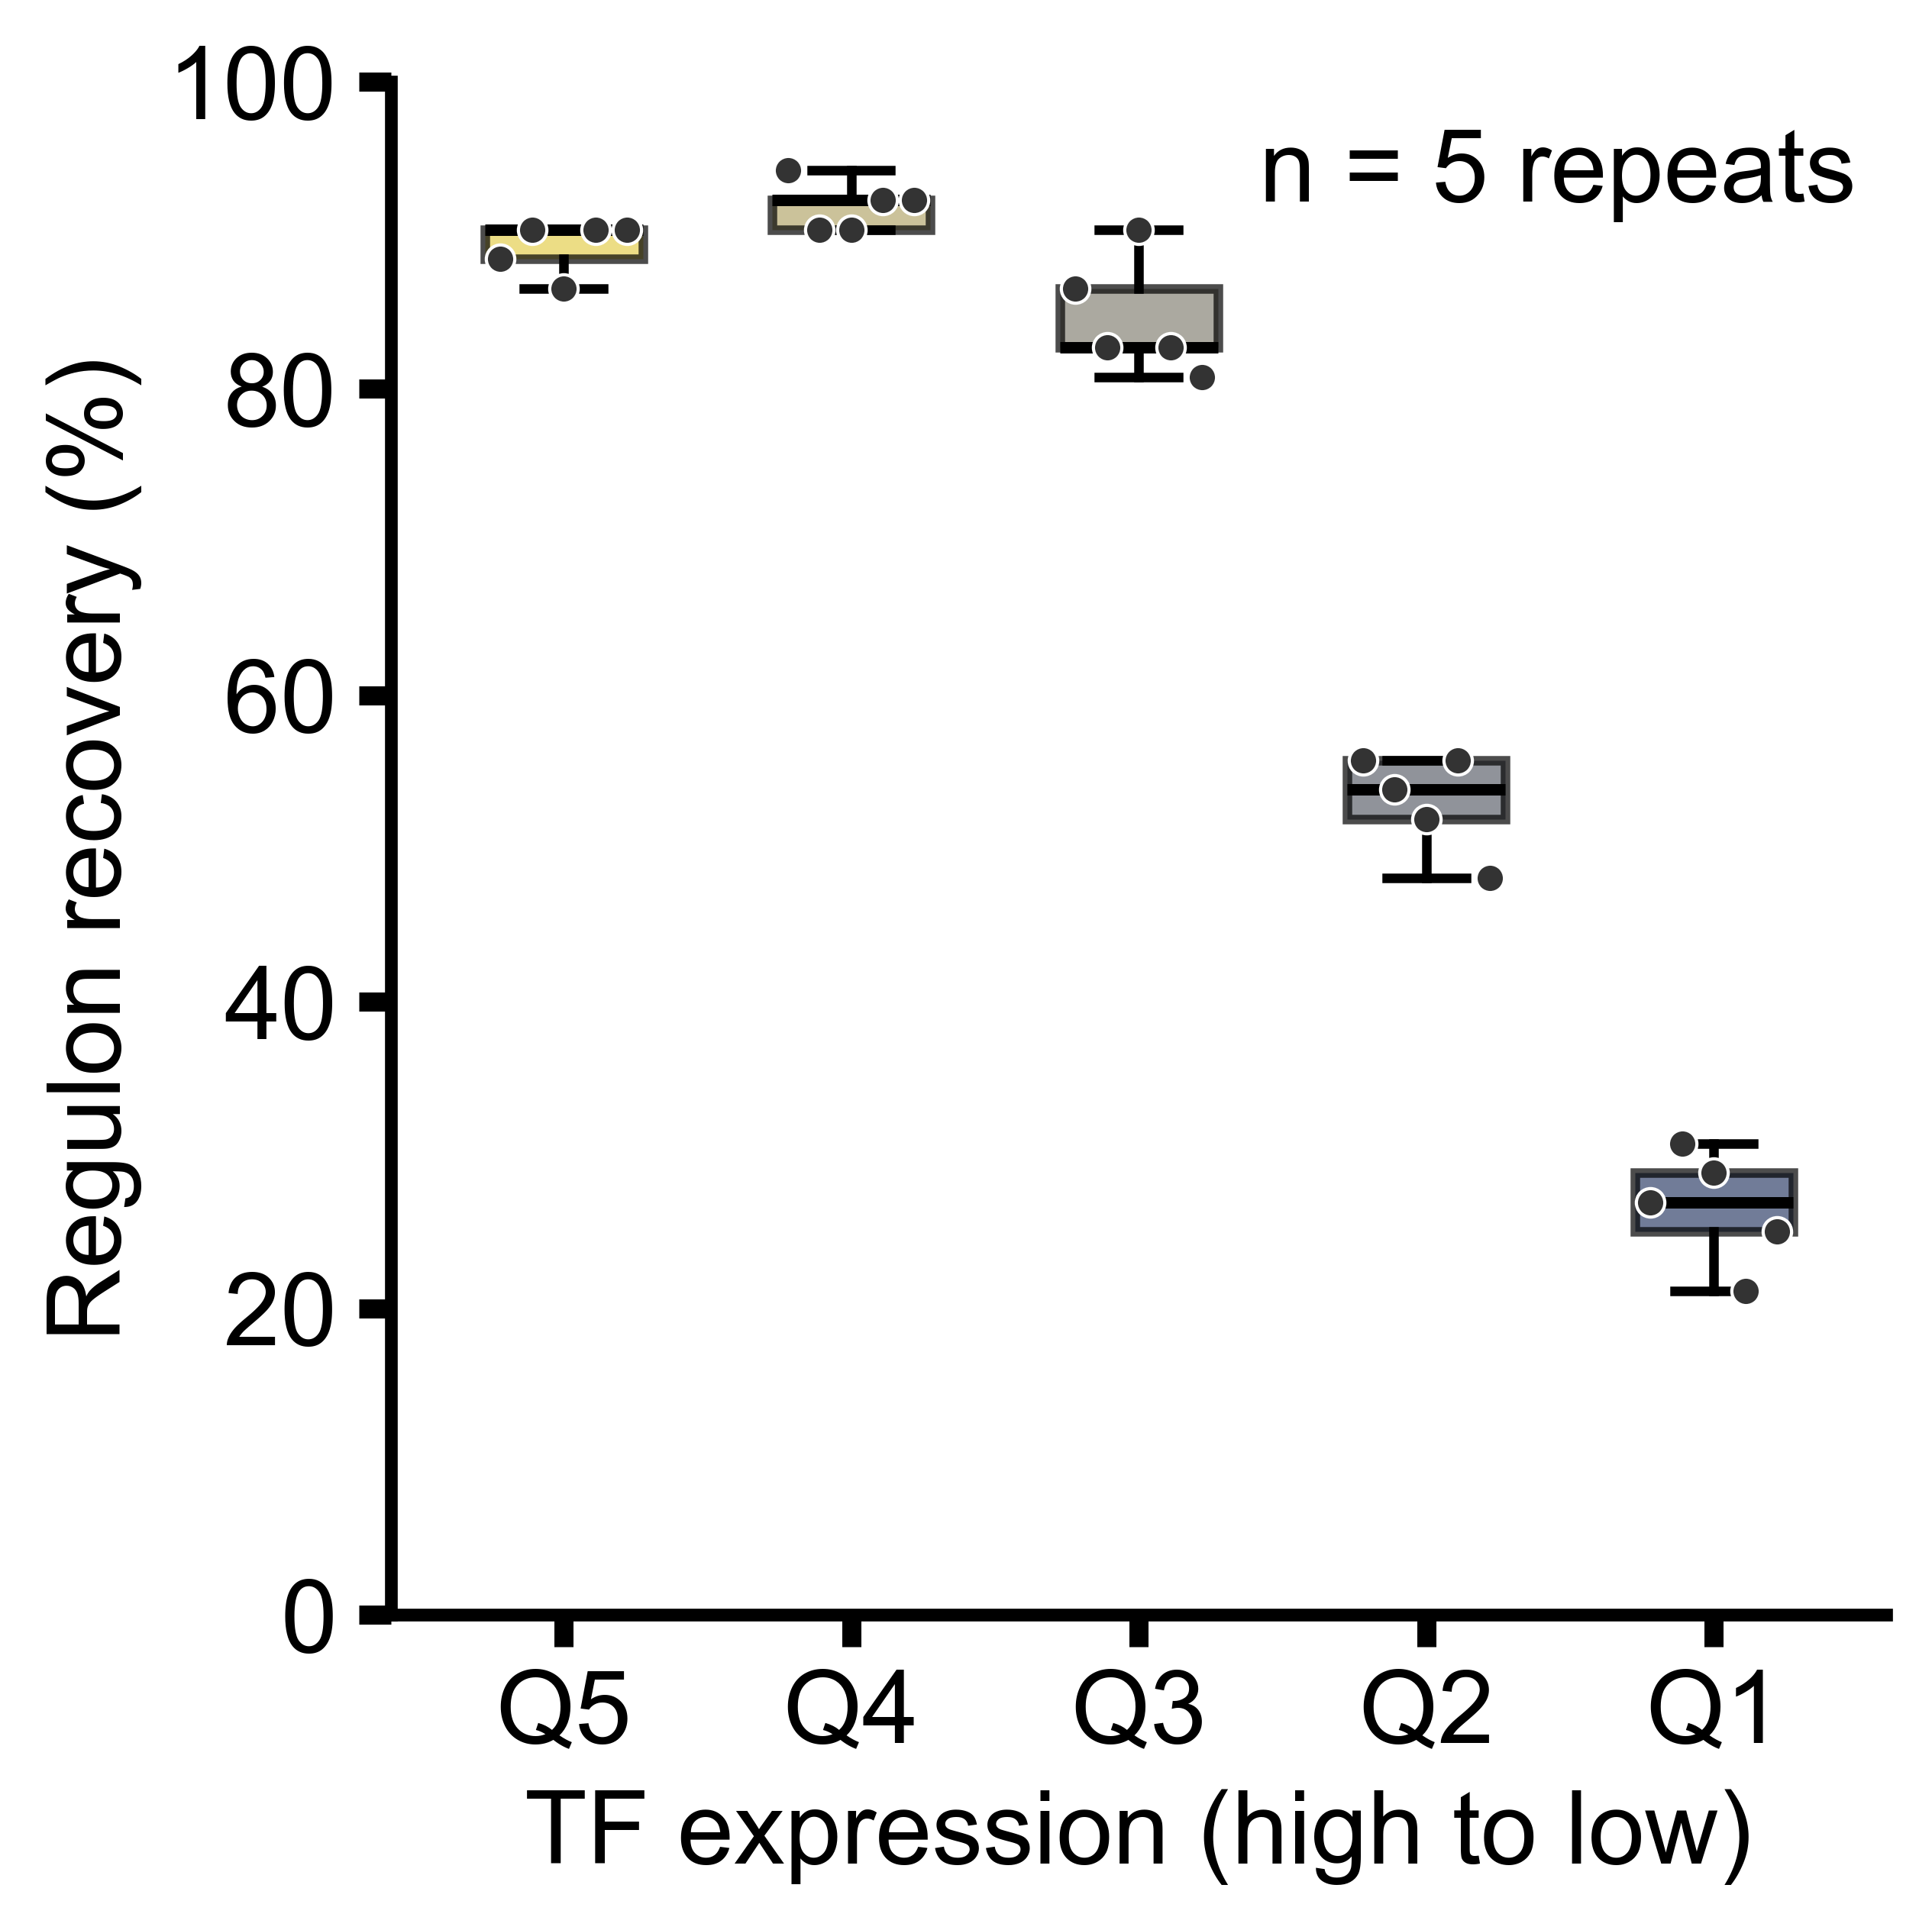

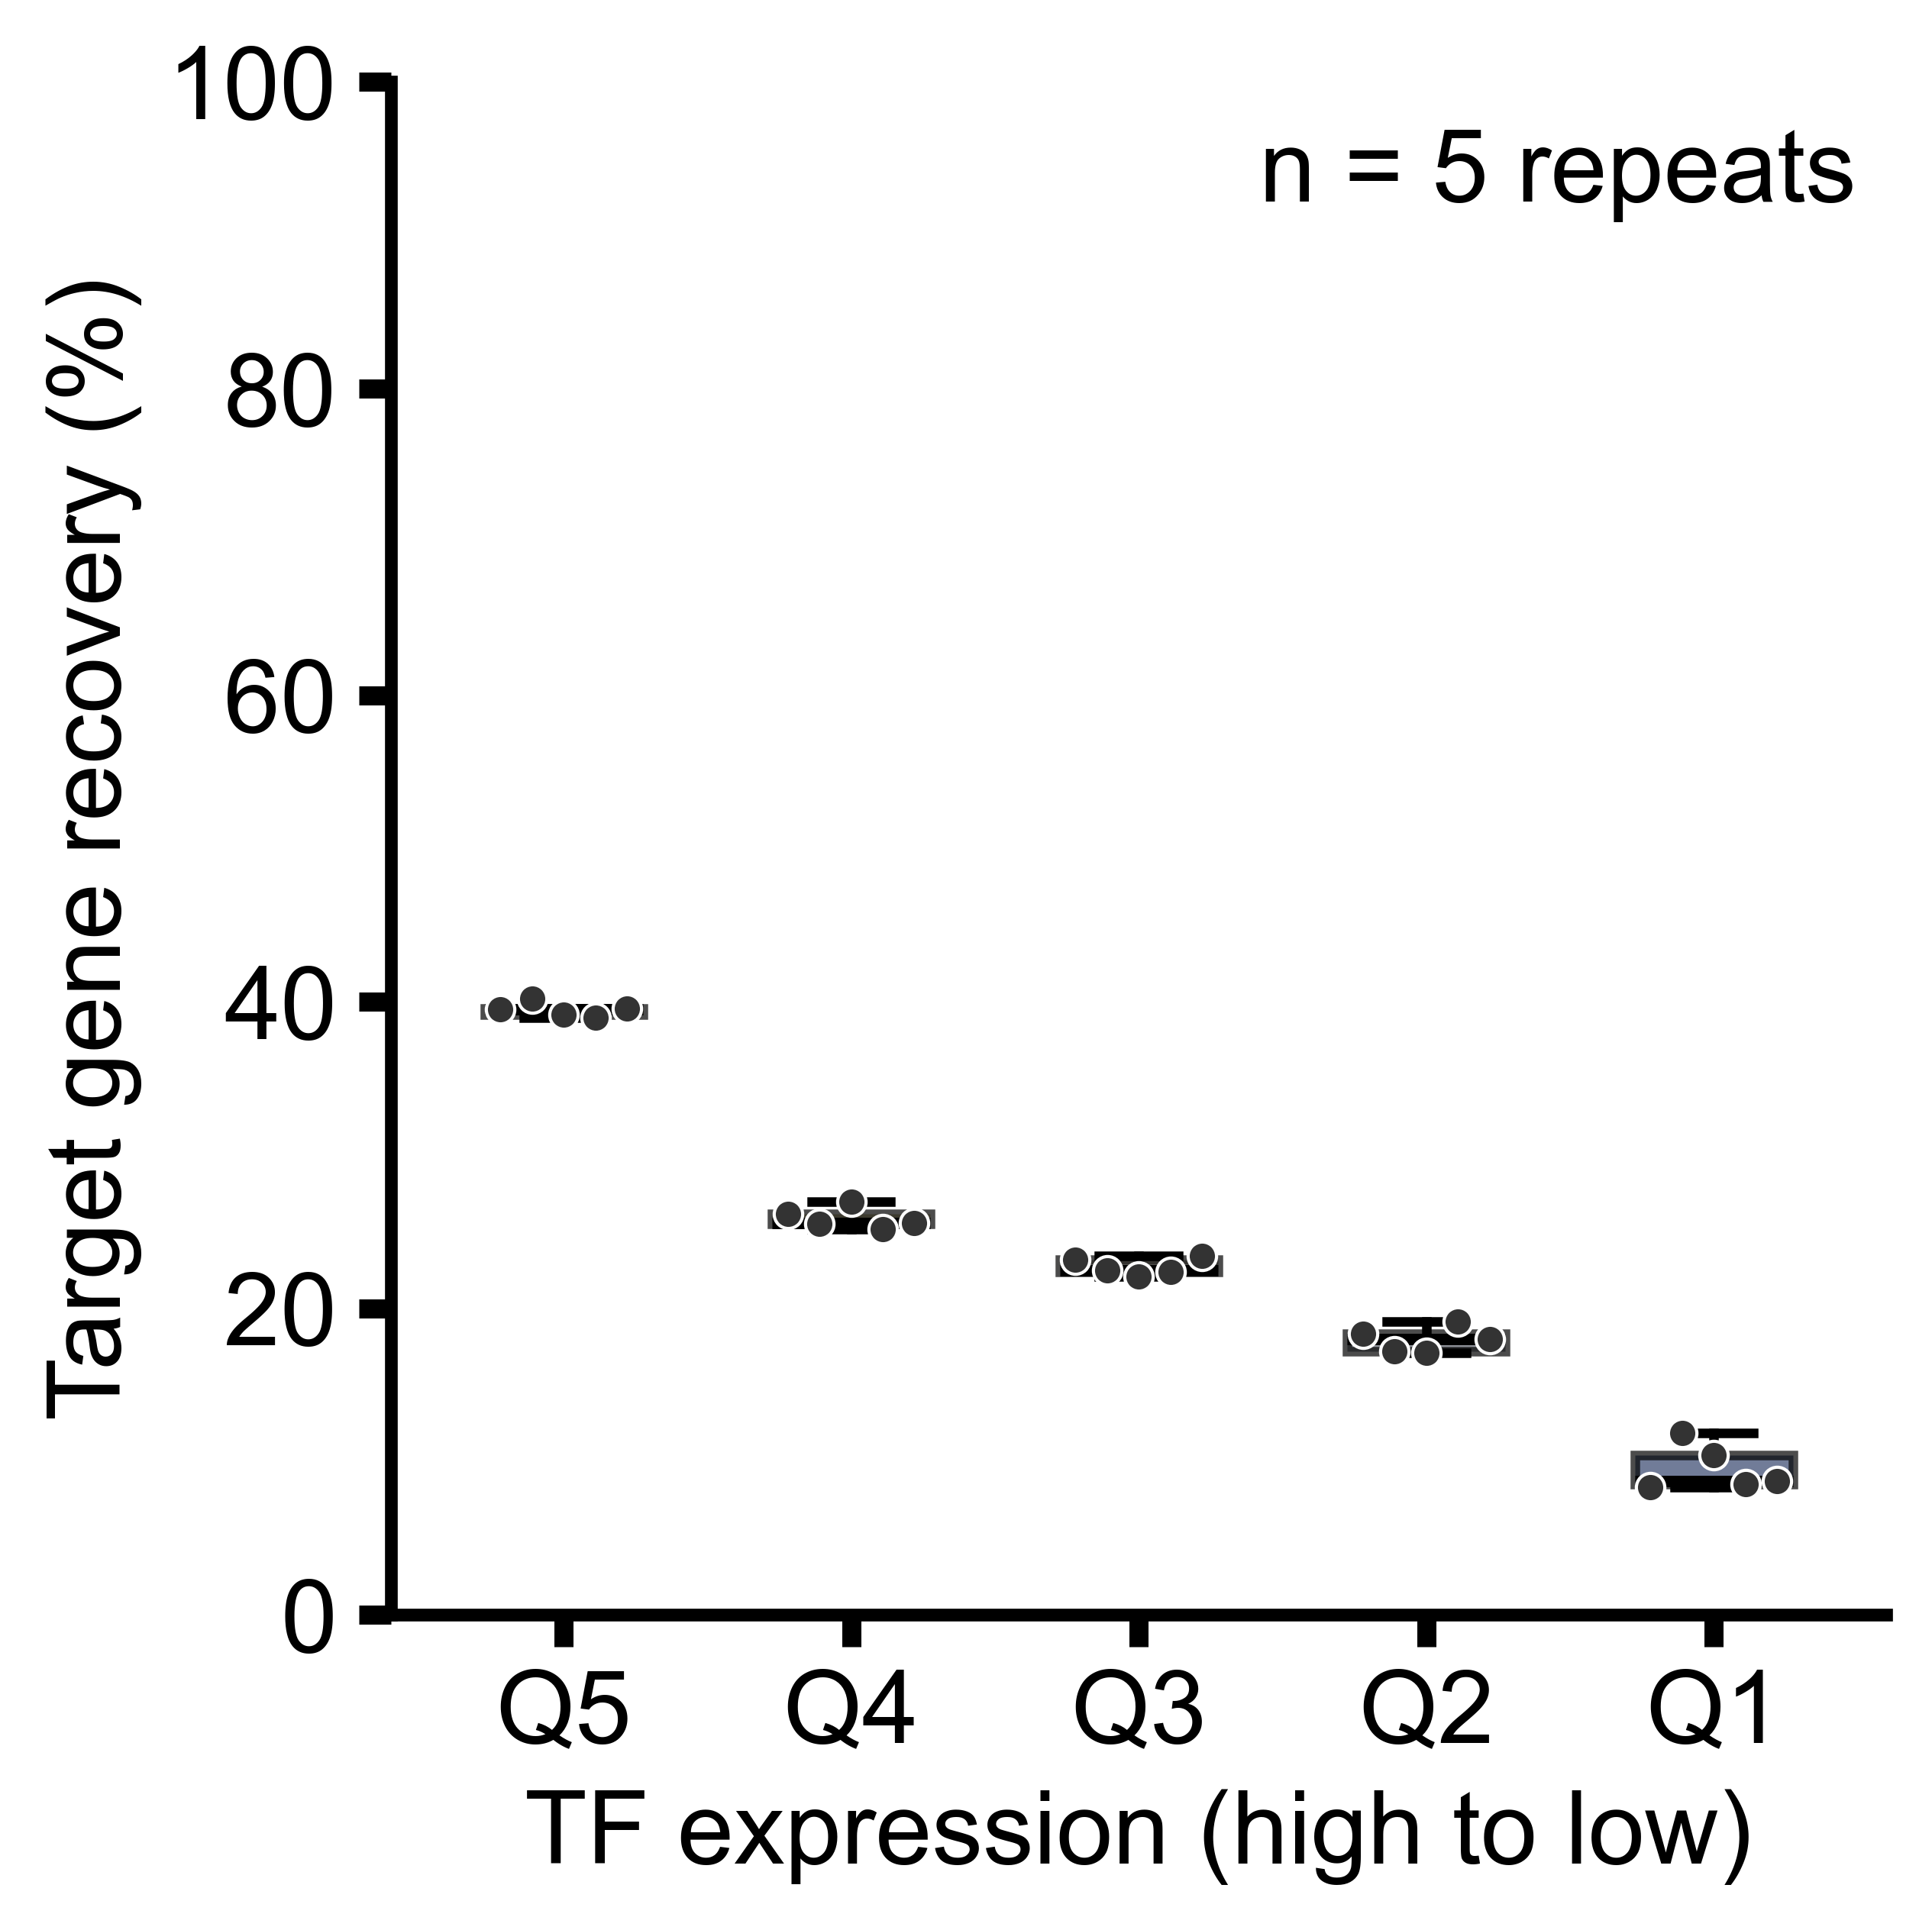

In [11]:
for values, ylabel, filename in [
    (expression_modules, 'Regulon recovery (%)', 'TF_expression_module_recovery.png'),
    (expression_targets, 'Target gene recovery (%)', 'TF_expression_target_recovery.png'),
]:
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    positions = np.arange(1, 6)
    boxes = ax.boxplot(values.to_numpy(), positions=positions, widths=0.55, patch_artist=True,
                       showfliers=False, whis=1.5,
                       boxprops={'linewidth': 1.5}, whiskerprops={'linewidth': 1.5},
                       capprops={'linewidth': 1.5},
                       medianprops={'color': 'black', 'linewidth': 1.8, 'zorder': 4})
    for position, column, box, color in zip(positions, values.columns, boxes['boxes'], expression_colors):
        box.set(facecolor=color, alpha=0.7)
        ax.scatter(position + np.linspace(-0.22, 0.22, len(values)), values[column],
                   s=20, color='#333333', edgecolors='white', linewidths=0.5, zorder=5)
    ax.set(xticks=positions, xticklabels=expression_order, xlabel='TF expression (high to low)',
           ylabel=ylabel, ylim=(0, 100), yticks=np.arange(0, 101, 20), xlim=(0.4, 5.6))
    ax.tick_params(axis='both', direction='out', length=5, width=3, bottom=True, left=True, top=False, right=False)
    for side in ['left', 'bottom']:
        ax.spines[side].set_linewidth(2)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.text(0.98, 0.97, 'n = 5 repeats', transform=ax.transAxes,
            ha='right', va='top', fontsize=FONT_SIZE)
    fig.tight_layout()
    fig.savefig(ROOT / 'figures' / filename, dpi=600, facecolor='white')
    fig.savefig(ROOT / 'figures' / Path(filename).with_suffix('.pdf'), dpi=300, facecolor='white')
    plt.show()